# LAB 1 - Bài 6 (Trang 45): So sánh Apriori và FP-Growth trên Groceries Dataset
SV: Hồng Kim Dung - 6451071009

In [1]:
!pip install -q mlxtend
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth
import warnings; warnings.filterwarnings("ignore")
print("Hồng Kim Dung - 6451071009")

Hồng Kim Dung - 6451071009


## Câu 1: Đọc dữ liệu và chuyển về dạng one-hot encoding

In [2]:
print("Hồng Kim Dung - 6451071009")

# Mỗi dòng của groceries.csv là một giao dịch, các mặt hàng cách nhau bằng dấu phẩy (số mặt hàng mỗi dòng khác nhau)
with open("groceries.csv") as f:
    transactions = [line.strip().split(",") for line in f if line.strip()]
print("Số giao dịch:", len(transactions))
print(transactions[:5])

Hồng Kim Dung - 6451071009
Số giao dịch: 9835
[['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups'], ['tropical fruit', 'yogurt', 'coffee'], ['whole milk'], ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads'], ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']]


In [3]:
print("Hồng Kim Dung - 6451071009")

te = TransactionEncoder()
df = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print("Kích thước (giao dịch x items):", df.shape)
df.iloc[:5, :8]

Hồng Kim Dung - 6451071009
Kích thước (giao dịch x items): (9835, 169)


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


## Câu 2: Apriori với min_sup từ 0.1% trở xuống, ghi nhận thời gian

In [4]:
print("Hồng Kim Dung - 6451071009")

# Các ngưỡng min_sup khảo sát (0.1% giảm dần). Xem giải thích về giới hạn 0.01% ở phần nhận xét.
min_sups = [0.001, 0.0009, 0.0008, 0.0007, 0.0006, 0.0005]
res = []
for s in min_sups:
    t0 = time.time()
    fi = apriori(df, min_support=s, use_colnames=True, low_memory=True)
    t = time.time() - t0
    res.append({"min_sup (%)": s*100, "so_tap_pho_bien": len(fi), "apriori_giay": round(t, 3)})
    print(f"min_sup={s*100:.2f}% -> {len(fi)} tập phổ biến, {t:.3f} giây")
apriori_df = pd.DataFrame(res); apriori_df

Hồng Kim Dung - 6451071009
min_sup=0.10% -> 13492 tập phổ biến, 4.880 giây
min_sup=0.09% -> 16188 tập phổ biến, 3.887 giây
min_sup=0.08% -> 19979 tập phổ biến, 3.602 giây
min_sup=0.07% -> 25570 tập phổ biến, 3.681 giây
min_sup=0.06% -> 34353 tập phổ biến, 5.010 giây
min_sup=0.05% -> 49580 tập phổ biến, 8.843 giây


,min_sup (%),so_tap_pho_bien,apriori_giay
0,0.10,13492,4.880
1,0.09,16188,3.887
2,0.08,19979,3.602
3,0.07,25570,3.681
4,0.06,34353,5.010
5,0.05,49580,8.843


## Câu 3: FP-Growth với cùng các ngưỡng min_sup, ghi nhận thời gian

In [5]:
print("Hồng Kim Dung - 6451071009")

res2 = []
for s in min_sups:
    t0 = time.time()
    fi = fpgrowth(df, min_support=s, use_colnames=True)
    t = time.time() - t0
    res2.append({"min_sup (%)": s*100, "so_tap_pho_bien": len(fi), "fpgrowth_giay": round(t, 3)})
    print(f"min_sup={s*100:.2f}% -> {len(fi)} tập phổ biến, {t:.3f} giây")
fp_df = pd.DataFrame(res2); fp_df

Hồng Kim Dung - 6451071009
min_sup=0.10% -> 13492 tập phổ biến, 458.162 giây
min_sup=0.09% -> 16188 tập phổ biến, 540.395 giây
min_sup=0.08% -> 19979 tập phổ biến, 674.716 giây
min_sup=0.07% -> 25570 tập phổ biến, 861.701 giây
min_sup=0.06% -> 34353 tập phổ biến, 1163.873 giây
min_sup=0.05% -> 49580 tập phổ biến, 1683.894 giây


,min_sup (%),so_tap_pho_bien,fpgrowth_giay
0,0.10,13492,458.162
1,0.09,16188,540.395
2,0.08,19979,674.716
3,0.07,25570,861.701
4,0.06,34353,1163.873
5,0.05,49580,1683.894


## Câu 4: Bảng tổng hợp so sánh

In [6]:
print("Hồng Kim Dung - 6451071009")

summary = apriori_df.merge(fp_df, on=["min_sup (%)","so_tap_pho_bien"])
summary["apriori/fpgrowth"] = (summary["apriori_giay"] / summary["fpgrowth_giay"]).round(2)
summary

Hồng Kim Dung - 6451071009


,min_sup (%),so_tap_pho_bien,apriori_giay,fpgrowth_giay,apriori/fpgrowth
0,0.10,13492,4.880,458.162,0.01
1,0.09,16188,3.887,540.395,0.01
2,0.08,19979,3.602,674.716,0.01
3,0.07,25570,3.681,861.701,0.00
4,0.06,34353,5.010,1163.873,0.00
5,0.05,49580,8.843,1683.894,0.01


## Câu 5: Biểu đồ so sánh thời gian xử lý

Hồng Kim Dung - 6451071009


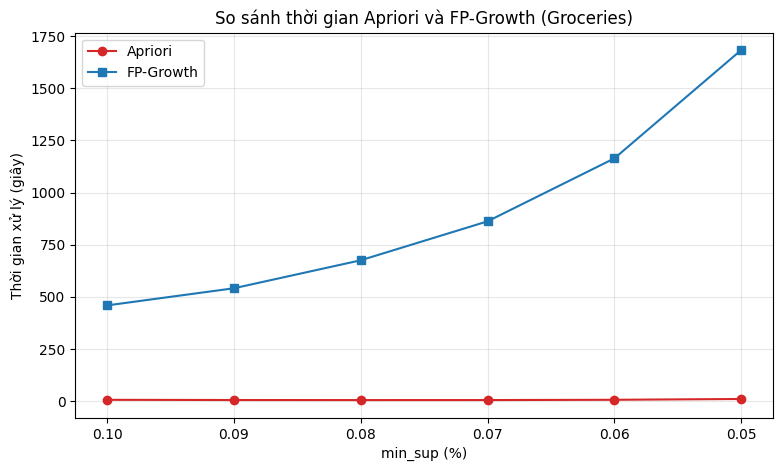

In [7]:
print("Hồng Kim Dung - 6451071009")

plt.figure(figsize=(9,5))
plt.plot(summary["min_sup (%)"], summary["apriori_giay"], "o-", label="Apriori", color="tab:red")
plt.plot(summary["min_sup (%)"], summary["fpgrowth_giay"], "s-", label="FP-Growth", color="tab:blue")
plt.xlabel("min_sup (%)"); plt.ylabel("Thời gian xử lý (giây)")
plt.title("So sánh thời gian Apriori và FP-Growth (Groceries)")
plt.gca().invert_xaxis(); plt.legend(); plt.grid(alpha=.3); plt.show()

Hồng Kim Dung - 6451071009


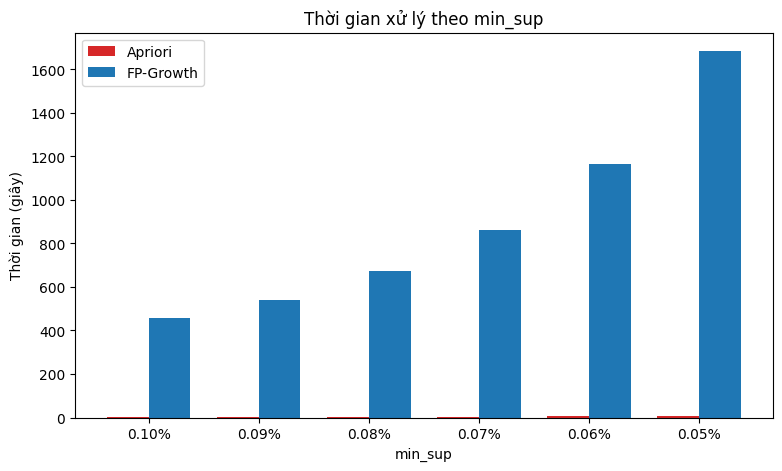

In [8]:
print("Hồng Kim Dung - 6451071009")

x = np.arange(len(summary)); w = 0.38
plt.figure(figsize=(9,5))
plt.bar(x - w/2, summary["apriori_giay"], w, label="Apriori", color="tab:red")
plt.bar(x + w/2, summary["fpgrowth_giay"], w, label="FP-Growth", color="tab:blue")
plt.xticks(x, [f"{v:.2f}%" for v in summary["min_sup (%)"]]); plt.xlabel("min_sup"); plt.ylabel("Thời gian (giây)")
plt.title("Thời gian xử lý theo min_sup"); plt.legend(); plt.show()

## Câu 6: Nhận xét và giải thích

**Nhận xét:**
Ở mọi mức min_sup khảo sát (từ 0.10% đến 0.05%), Apriori và FP-Growth cho cùng số tập phổ biến, chỉ khác nhau về thời gian xử lý. Khi min_sup giảm, số tập phổ biến tăng nhanh (từ 13.492 lên 49.580 tập) và thời gian xử lý của FP-Growth tăng mạnh (từ khoảng 458 giây lên khoảng 1.684 giây), còn Apriori (chạy với low_memory=True) tăng rất ít (từ khoảng 4 giây lên khoảng 9 giây). Trong thực nghiệm này FP-Growth chậm hơn Apriori nhiều lần, trái với lý thuyết. Theo lý thuyết, FP-Growth thường nhanh hơn vì chỉ quét dữ liệu hai lần để xây cây FP-tree và khai thác trực tiếp mà không sinh tập ứng viên, trong khi Apriori phải sinh ứng viên và quét lại dữ liệu nhiều lần. Kết quả thực nghiệm khác lý thuyết là do cách cài đặt của thư viện mlxtend trên Google Colab: bản FP-Growth của thư viện xử lý bảng dữ liệu dạng one-hot dày kém hiệu quả, còn Apriori ở chế độ low_memory được tối ưu hơn. Với dữ liệu nhỏ như Groceries (9.835 giao dịch, 169 mặt hàng), ưu thế của FP-Growth chưa thể hiện rõ.